Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Imports

In [2]:
import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers
from tensorflow.keras import models
from tensorflow.keras import callbacks
from tensorflow.keras import optimizers

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

Reproducibility

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

Dataset Paths

In [4]:
TRAIN_DIR = "/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Train"

VAL_DIR = "/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Validation"

TEST_DIR = "/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Test"

Hyperparameters

In [5]:
IMAGE_SIZE = (224,224)

BATCH_SIZE = 32

EPOCHS_STAGE1 = 20

EPOCHS_STAGE2 = 10

LEARNING_RATE = 1e-3

FINE_TUNE_LR = 1e-5

NUM_CLASSES = 3

Load Dataset (Modern TensorFlow)

In [6]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 1990 files belonging to 3 classes.
Found 427 files belonging to 3 classes.
Found 428 files belonging to 3 classes.


Print Class Names

In [7]:
class_names = train_ds.class_names

print(class_names)

['High', 'Low', 'Moderate']


Optimize the Dataset Pipeline

In [11]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(AUTOTUNE)

val_ds = val_ds.cache().prefetch(AUTOTUNE)

test_ds = test_ds.cache().prefetch(AUTOTUNE)

Create Data Augmentation Layer

In [12]:
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(
        factor=0.03,
        fill_mode="reflect"
    ),

    layers.RandomZoom(
        height_factor=0.15,
        width_factor=0.15,
        fill_mode="reflect"
    ),

    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),

    layers.RandomBrightness(
        factor=0.10
    )

], name="data_augmentation")

Visualize Augmentation

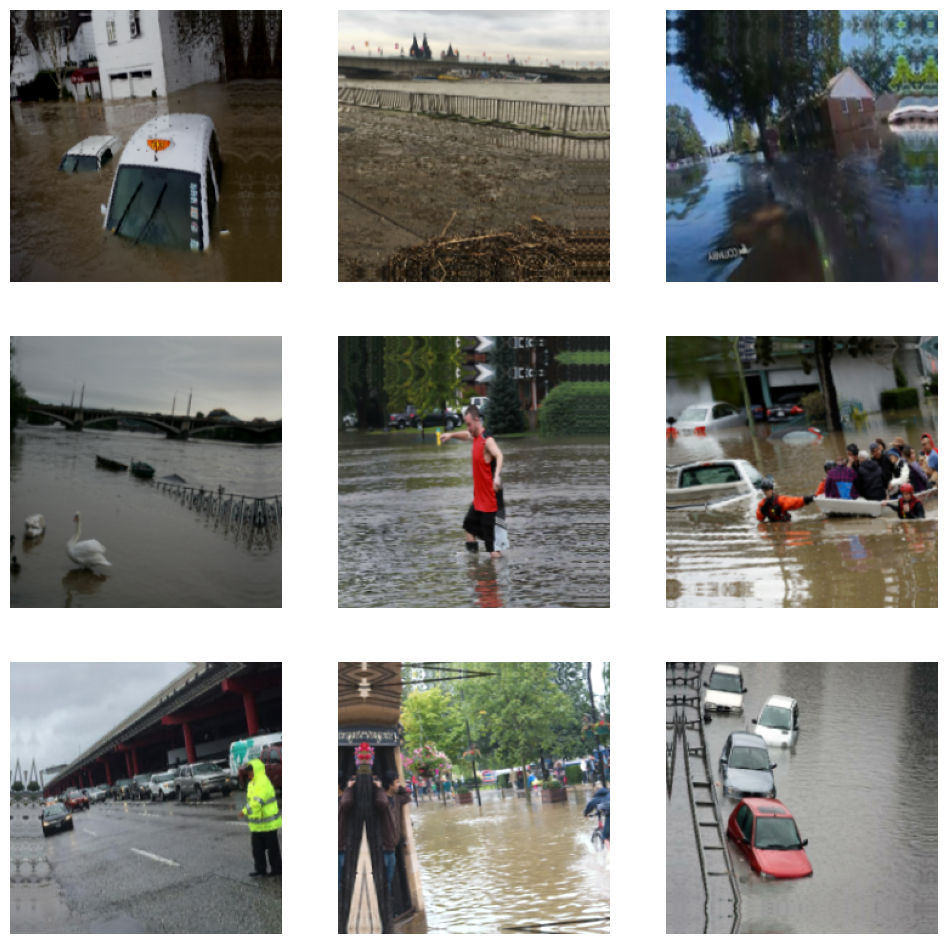

In [13]:
plt.figure(figsize=(12, 12))

for images, labels in train_ds.take(1):

    augmented = data_augmentation(images)

    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(tf.cast(augmented[i], tf.uint8))

        plt.axis("off")

plt.show()

Create the EfficientNetB0 Base Model

In [15]:
base_model = EfficientNetB0(

    include_top=False,

    weights="imagenet",

    input_shape=(224, 224, 3)

)

base_model.trainable = False

Build the Complete Model

In [16]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(256, activation="relu")(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(128, activation="relu")(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

Verify the Model

In [17]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,415,910 (16.85 MB)

 Trainable params: 363,779 (1.39 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

Compile Model

In [18]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=["accuracy"]

)

Create Output Folders

In [19]:
MODEL_DIR = "/content/drive/MyDrive/CrisisWeave_Project/03_Models/CNN"

RESULT_DIR = "/content/drive/MyDrive/CrisisWeave_Project/04_Results/CNN"

os.makedirs(MODEL_DIR, exist_ok=True)

os.makedirs(RESULT_DIR, exist_ok=True)

Callbacks

In [28]:
early_stop = tf.keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True

)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.2,

    patience=2,

    min_lr=1e-6

)

checkpoint = tf.keras.callbacks.ModelCheckpoint(

    filepath=os.path.join(MODEL_DIR, "best_model.keras"),

    monitor="val_loss",

    mode="min",

    save_best_only=True,

    verbose=1

)

Train Stage 1

In [29]:
history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS_STAGE1,

    callbacks=[

        early_stop,

        reduce_lr,

        checkpoint

    ]

)

Epoch 1/20
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.8134 - loss: 0.4744
Epoch 1: val_loss improved from None to 0.70129, saving model to /content/drive/MyDrive/CrisisWeave_Project/03_Models/CNN/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CrisisWeave_Project/03_Models/CNN/best_model.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - accuracy: 0.8030 - loss: 0.4862 - val_accuracy: 0.7190 - val_loss: 0.7013 - learning_rate: 8.0000e-06
Epoch 2/20
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.7968 - loss: 0.4933
Epoch 2: val_loss did not improve from 0.70129
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.8030 - loss: 0.4685 - val_accuracy: 0.7190 - val_loss: 0.7016 - learning_rate: 8.0000e-06
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.8188 - loss: 0.4411
Epoch 3: val_loss did not improve from 0.70129
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 116ms/step - accuracy: 0.8211 - loss: 0.4430 - val_accuracy: 0.7190 - val_loss: 0.7

Load Best Model

In [30]:
best_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/CrisisWeave_Project/03_Models/CNN/best_model.keras"
)

Evaluate on Test Set

In [31]:
test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"\nTest Accuracy : {test_accuracy:.4f}")
print(f"Test Loss     : {test_loss:.4f}")

14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.6589 - loss: 0.8120

Test Accuracy : 0.6589
Test Loss     : 0.8120


Generate Predictions

In [32]:
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = best_model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

Classification Report

In [33]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

        High       0.79      0.60      0.68       146
         Low       0.77      0.63      0.70       141
    Moderate       0.52      0.74      0.61       141

    accuracy                           0.66       428
   macro avg       0.70      0.66      0.66       428
weighted avg       0.70      0.66      0.66       428



Confusion Matrix

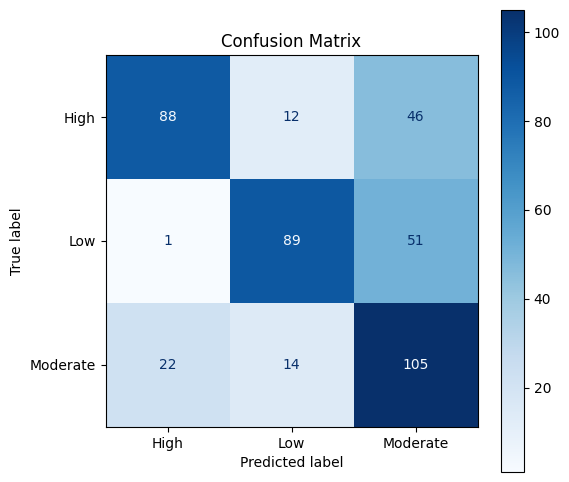

In [34]:
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

Save Confusion Matrix

In [35]:
fig.savefig(
    os.path.join(
        RESULT_DIR,
        "confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

Save Training Accuracy Graph

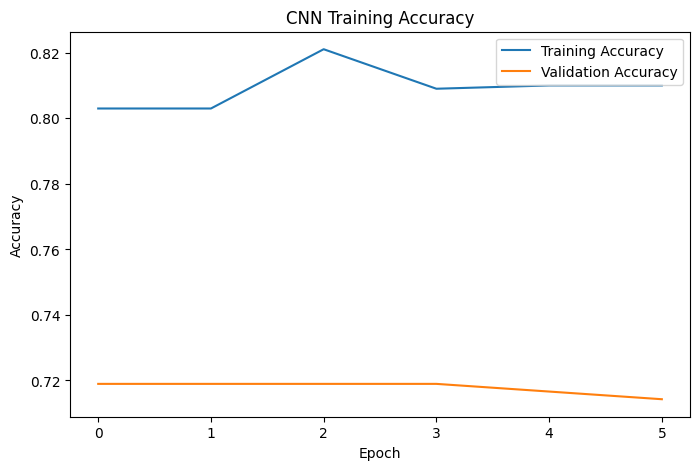

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.savefig(os.path.join(RESULT_DIR, "accuracy.png"), dpi=300)

plt.show()

Save Training Loss Graph

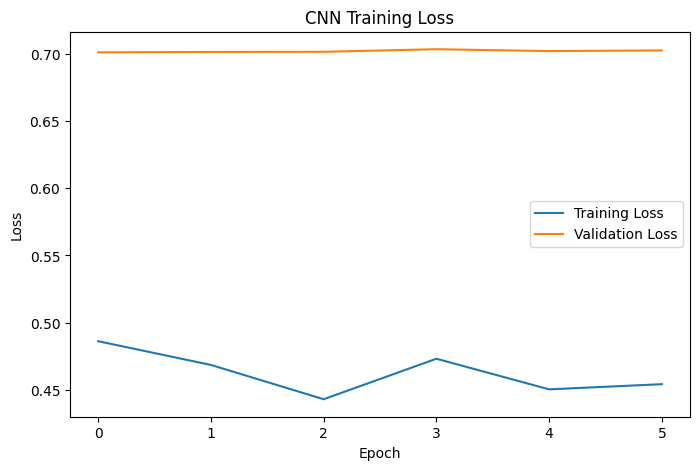

In [43]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.savefig(os.path.join(RESULT_DIR, "loss.png"), dpi=300)

plt.show()

Save Classification Report

In [45]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print(report)

with open(os.path.join(RESULT_DIR, "classification_report.txt"), "w") as f:
    f.write(report)

              precision    recall  f1-score   support

        High       0.79      0.60      0.68       146
         Low       0.77      0.63      0.70       141
    Moderate       0.52      0.74      0.61       141

    accuracy                           0.66       428
   macro avg       0.70      0.66      0.66       428
weighted avg       0.70      0.66      0.66       428



Save Model Summary

In [46]:
with open(os.path.join(RESULT_DIR, "model_summary.txt"), "w") as f:
    model.summary(print_fn=lambda x: f.write(x + "\n"))

# ==========================================
# STAGE 2 FINE-TUNING (EXPERIMENT)
# Result: Validation performance decreased.
# Not used in final model.
# ==========================================

Stage 2 (Fine-Tuning)

In [36]:
# Unfreeze EfficientNetB0
base_model.trainable = True

# Freeze all except the last 40 layers
for layer in base_model.layers[:-40]:
    layer.trainable = False

print("Trainable layers:", sum([layer.trainable for layer in base_model.layers]))

Trainable layers: 40


Recompile

In [37]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=["accuracy"]

)

Fine-Tuning Training

In [40]:
history_finetune = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=10,

    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ]

)

Epoch 1/10
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.6637 - loss: 0.7239
Epoch 1: val_loss did not improve from 0.70129
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.6779 - loss: 0.7219 - val_accuracy: 0.6417 - val_loss: 0.7590 - learning_rate: 1.0000e-06
Epoch 2/10
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.6764 - loss: 0.7168
Epoch 2: val_loss did not improve from 0.70129
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - accuracy: 0.6698 - loss: 0.7307 - val_accuracy: 0.6464 - val_loss: 0.7699 - learning_rate: 1.0000e-06
Epoch 3/10
62/63 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.6935 - loss: 0.7166
Epoch 3: val_loss did not improve from 0.70129
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 105ms/step - accuracy: 0.6945 - loss: 0.7163 - val_accuracy: 0.6393 - val_loss: 0.7755 - learning_rate: 1.0000e-06
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.6784 - loss: 0.7224
Epoch 4: val_loss did not improve from 0.70129
63/63 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/s